# Centro de datos inteligente: análisis de Fases I y II
**Julio Javier Fernández Garín · Unit 4002 · 2026–2027**

Todos los datos son simulados. Este notebook amplía el mismo sistema de Fase I.
La simulación sirve para demostrar un método reproducible; no demuestra una mejora real.
Ejecuta las celdas en orden después de leer el README. Las funciones están en `src/analisis.py`.


## 1. Importación y localización de la carpeta
La ruta se resuelve desde la carpeta principal o desde `notebooks`. No hay rutas personales de Windows.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display, Image

candidatos = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'centro_datos_julio']
RAIZ = next((p for p in candidatos if (p / 'src' / 'analisis.py').exists()), None)
if RAIZ is None:
    raise FileNotFoundError('Descomprime la carpeta completa y consulta README.md.')
sys.path.insert(0, str(RAIZ / 'src'))
from analisis import (CONFIG, VARIABLES, generar_datos, limpiar_datos, agregar_por_dia,
    resumen_descriptivo, analizar_relacion, probabilidades, contraste_pareado,
    comprobar_resultados, crear_figuras)
print('Carpeta del proyecto encontrada. Semilla:', CONFIG['semilla'])


Carpeta del proyecto encontrada. Semilla: 4002


## 2. Generación justificada y carga
30 pares × 24 horas × 2 escenarios. Los dos escenarios de cada par comparten IT y ambiente. Se añade un duplicado y se vacían dos sumas para mostrar la limpieza. Son anomalías intencionadas, no fallos reales de sensores.

La parametrización completa está en `datos/DICCIONARIO.md`. Los eventos tienen una semilla separada: 4003.

In [2]:
bruto, eventos = generar_datos()
(RAIZ / 'datos').mkdir(exist_ok=True)
bruto.to_csv(RAIZ / 'datos' / 'horario_bruto.csv', index=False)
eventos.to_csv(RAIZ / 'datos' / 'eventos_diarios.csv', index=False)
bruto = pd.read_csv(RAIZ / 'datos' / 'horario_bruto.csv')
eventos = pd.read_csv(RAIZ / 'datos' / 'eventos_diarios.csv')
print('Dimensión bruta:', bruto.shape, '| Eventos:', eventos.shape)
display(bruto.head())


dia,hora,escenario,p_it_kw,temperatura_exterior_c,p_refrigeracion_kw,p_otros_kw,p_total_kw,pue_horario
1,0,base,111.311986,19.445232,27.192131,37.0,175.504117,1.576687
1,0,mejorado,111.311986,19.445232,13.615581,27.0,151.927566,1.364881
1,1,base,109.578145,19.827270,25.363391,37.0,171.941537,1.569123
1,1,mejorado,109.578145,19.827270,12.977147,27.0,149.555292,1.364828
1,2,base,112.002077,20.103887,24.166843,37.0,173.168920,1.546122


Dimensión bruta: (1441, 9) | Eventos: (30, 4)


## 3. Inspección y preparación
`limpiar_datos` recibe la tabla, elimina copias exactas, comprueba claves y reconstruye totales ausentes mediante IT + refrigeración + otros. Devuelve la tabla limpia y un registro. No se eliminan extremos ni se interpolan sensores.

In [3]:
limpio, calidad = limpiar_datos(bruto)
diario = agregar_por_dia(limpio)
limpio.to_csv(RAIZ / 'datos' / 'horario_limpio.csv', index=False)
print(json.dumps(calidad, ensure_ascii=False, indent=2))
print('Matriz limpia:', limpio.shape, '| Matriz diaria:', diario.shape)
display(diario.head())


dia,escenario,e_it_kwh,e_total_kwh,e_refrigeracion_kwh,temperatura_exterior_media_c,p_it_media_kw,pue_diario
1,base,2747.033509,4421.672620,786.639111,24.718437,114.459730,1.609617
1,mejorado,2747.033509,3795.080910,400.047401,24.718437,114.459730,1.381520
2,base,2677.222398,4387.332090,822.109692,24.720162,111.550933,1.638763
2,mejorado,2677.222398,3899.992098,574.769700,24.720162,111.550933,1.456731
3,base,2900.993199,4564.819733,775.826534,23.780522,120.874717,1.573537


{
  "filas_brutas": 1441,
  "duplicados_exactos": 1,
  "totales_reconstruidos": 2,
  "filas_limpias": 1440,
  "ausentes_finales": 0
}
Matriz limpia: (1440, 9) | Matriz diaria: (60, 8)


## 4. Funciones auxiliares
Las operaciones repetidas se encapsulan en funciones, con entrada, proceso y retorno documentados.

- `agregar_por_dia`: tabla horaria → energías y PUE diarios.
- `resumen_descriptivo`: tabla y columnas → medidas con `ddof=1`.
- `probabilidades`: eventos y medias IT → parámetros y probabilidades.
- `contraste_pareado`: días emparejados → diferencia media, t, p e intervalo.
- `comprobar_resultados`: tablas y resultados → controles de coherencia.

Lee las definiciones de `src/analisis.py`; la guía explica todas las funciones. El notebook las llama sin copiar su implementación.

## 5. Estadística descriptiva
La desviación usa n−1. Se calculan medidas diarias para las decisiones; las horas se describen sin atribuirles independencia. La moda exacta no aporta información en las potencias continuas; sí en los recuentos de avisos.

In [4]:
descriptiva_horaria = resumen_descriptivo(limpio, VARIABLES)
descriptiva_diaria = resumen_descriptivo(diario, ['e_total_kwh', 'p_it_media_kw', 'pue_diario'])
display(descriptiva_diaria.round(4))
print('Moda de avisos:', eventos.avisos.mode().tolist())
print('Frecuencias de avisos:')
print(eventos.avisos.value_counts().sort_index().to_string())


grupo,variable,n,media,mediana,s,varianza,cv_pct,minimo,q1,q3,p95,maximo,rango
base,e_total_kwh,30,4617.2582,4595.3606,151.8800,23067.5272,3.2894,4387.3321,4496.3357,4743.0013,4837.5404,5032.6342,645.3021
base,p_it_media_kw,30,120.8003,122.0008,5.3038,28.1299,4.3905,111.1726,117.2351,124.1279,129.7284,131.4250,20.2525
base,pue_diario,30,1.5936,1.5952,0.0345,0.0012,2.1656,1.5228,1.5743,1.6122,1.6445,1.6841,0.1613
mejorado,e_total_kwh,30,4041.7091,4045.0129,150.2379,22571.4152,3.7172,3727.5740,3976.6911,4136.9630,4295.4324,4342.4632,614.8892
mejorado,p_it_media_kw,30,120.8003,122.0008,5.3038,28.1299,4.3905,111.1726,117.2351,124.1279,129.7284,131.4250,20.2525
mejorado,pue_diario,30,1.3946,1.3934,0.0244,0.0006,1.7477,1.3512,1.3791,1.4150,1.4249,1.4567,0.1055


Moda de avisos: [0]
Frecuencias de avisos:
avisos
0    12
1     8
2     7
3     3


## 6. Relación entre variables
Se calcula Pearson en 30 medias diarias del escenario base: relación aproximadamente lineal entre temperatura exterior y refrigeración. Spearman es una comparación descriptiva auxiliar. No se usan las 720 horas como réplicas independientes. La asociación fue parcialmente impuesta por el generador; no es prueba causal.

In [5]:
relacion = analizar_relacion(diario)
print(json.dumps(relacion, ensure_ascii=False, indent=2))


{
  "n": 30,
  "covarianza": 102.06005015174085,
  "pearson_r": 0.656144359546976,
  "spearman_rho": 0.5016685205784205
}


## 7. Probabilidad y distribuciones
Binomial: rechazos en 20 inspecciones hipotéticas independientes, p constante. Poisson: avisos por día a tasa constante y con incrementos independientes. Sus parámetros se estiman de 600 inspecciones y 30 días, respectivamente.

Normal: potencia IT media de un día; no una hora individual. Se aproxima por una Normal con media y s estimadas de 30 días. La prueba de Shapiro no confirma la distribución: solo informa de compatibilidad. Las probabilidades son plug-in y no incluyen incertidumbre en los parámetros.

In [6]:
prob = probabilidades(eventos, diario)
print(json.dumps(prob, ensure_ascii=False, indent=2))
print('P(al menos un rechazo en 20):', f"{100*prob['binomial_al_menos_uno']:.2f}%")
print('P(al menos tres avisos/día):', f"{100*prob['poisson_al_menos_tres']:.2f}%")
print('P(IT media diaria > 130 kW):', f"{100*prob['normal_mayor_130']:.2f}%")


{
  "n_binomial": 20,
  "inspecciones_totales": 600,
  "rechazos_totales": 9,
  "p_estimado": 0.015,
  "binomial_al_menos_uno": 0.2608635666528982,
  "binomial_manual": 0.26086356665289845,
  "lambda_estimada": 1.0333333333333334,
  "avisos_totales": 31,
  "poisson_al_menos_tres": 0.08653376524385721,
  "poisson_manual": 0.08653376524385736,
  "mu_it_kw": 120.80029470649102,
  "s_it_kw": 5.303767104235132,
  "z_130": 1.734560570384565,
  "normal_mayor_130": 0.04140933426203396,
  "normal_manual": 0.041409334262033956,
  "fraccion_empirica_mayor_130": 0.06666666666666667,
  "shapiro_it_p": 0.5073031428677783,
  "moda_avisos": [
    0
  ],
  "frecuencia_moda_avisos": 12
}
P(al menos un rechazo en 20): 26.09%
P(al menos tres avisos/día): 8.65%
P(IT media diaria > 130 kW): 4.14%


## 8. Visualizaciones
Líneas: variación entre pares. Barras: consumo medio por escenario (eje desde cero). Histograma: distribución de las medias IT. Dispersión: ambiente frente a refrigeración. Mapa de calor: perfil por día y hora. Q–Q: diagnóstico de aproximación normal. Las dos primeras figuras recuperan los modelos de Fase I.

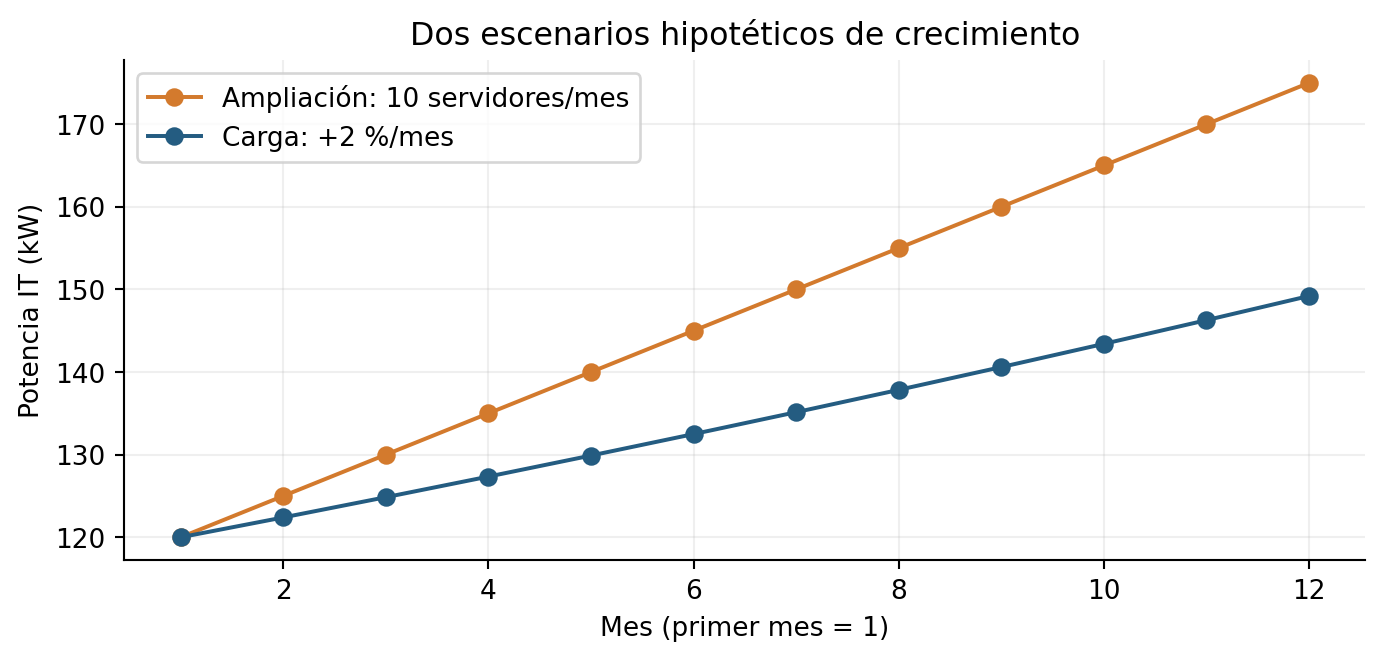

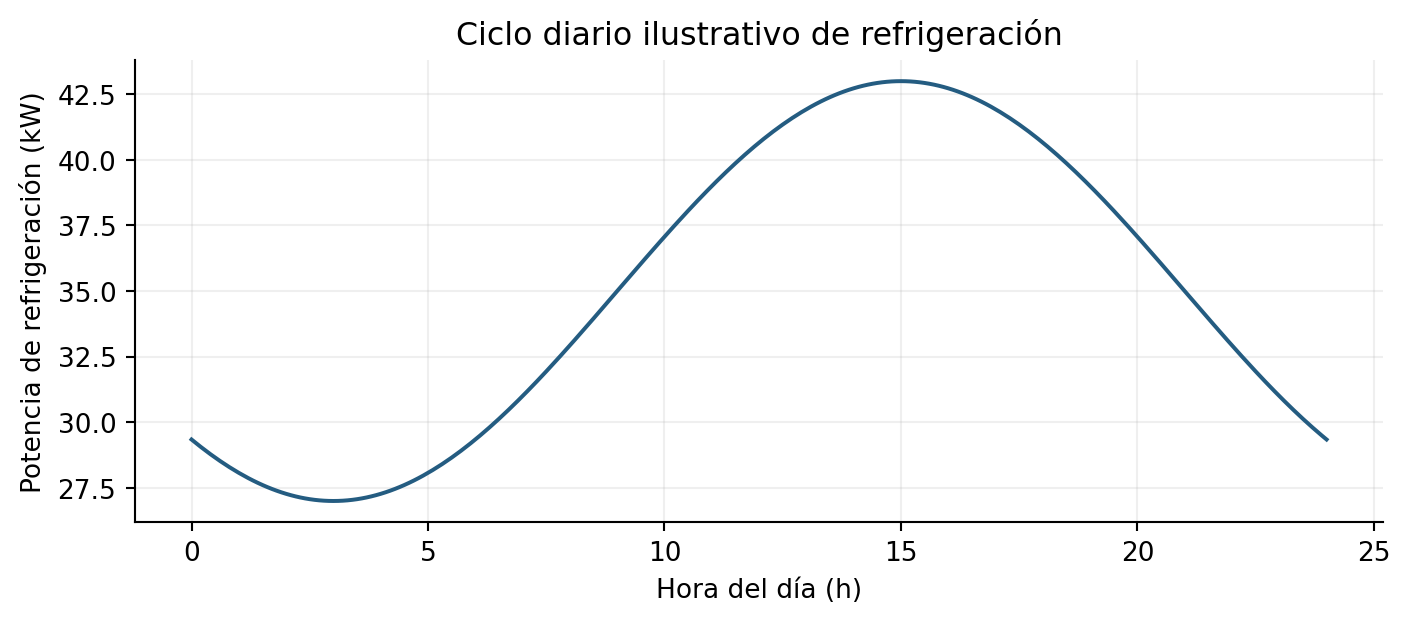

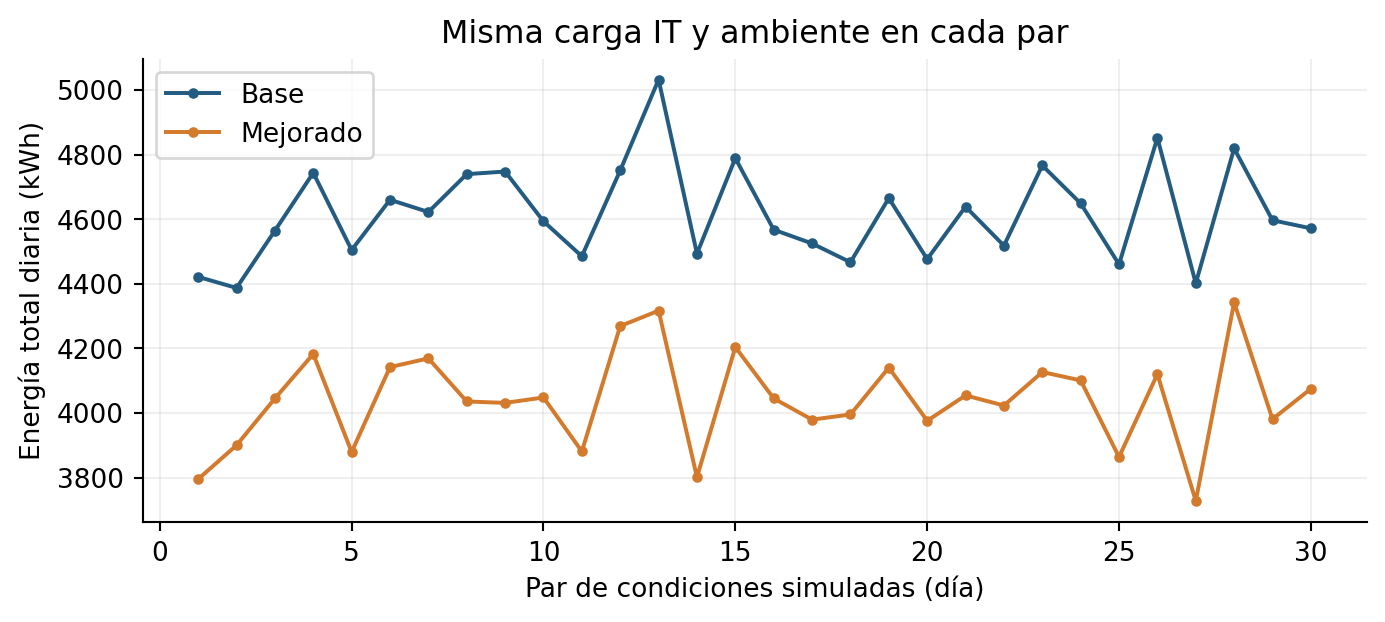

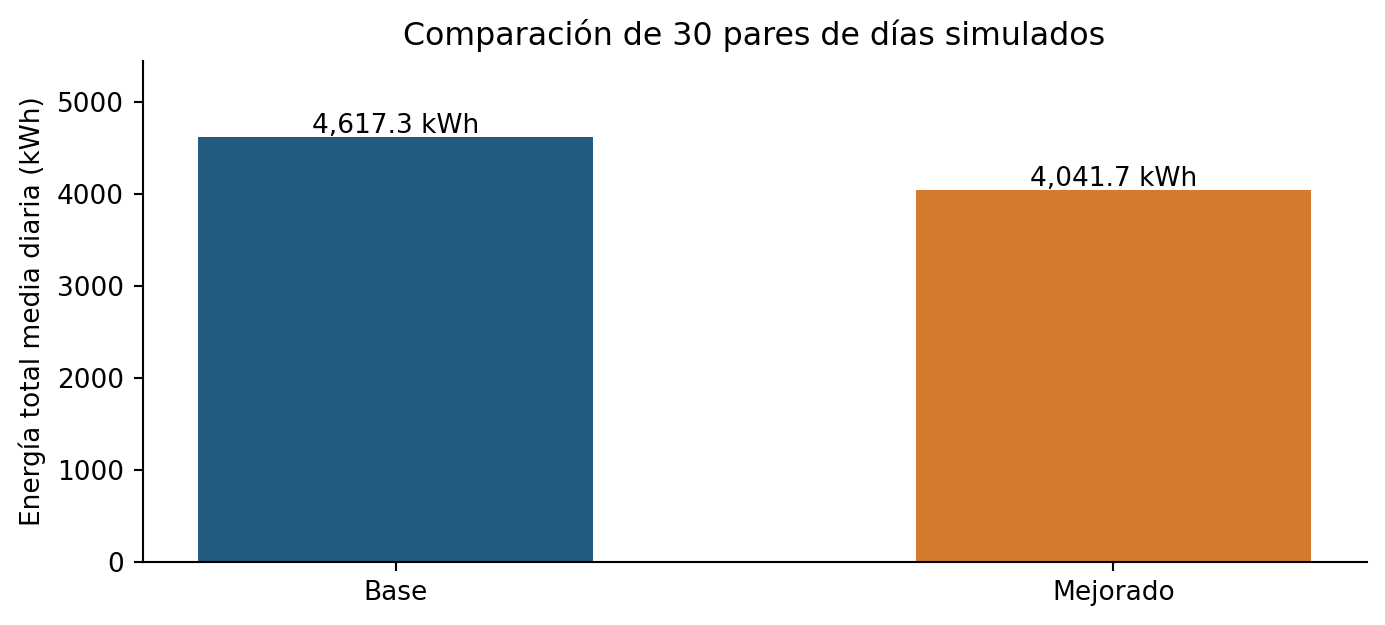

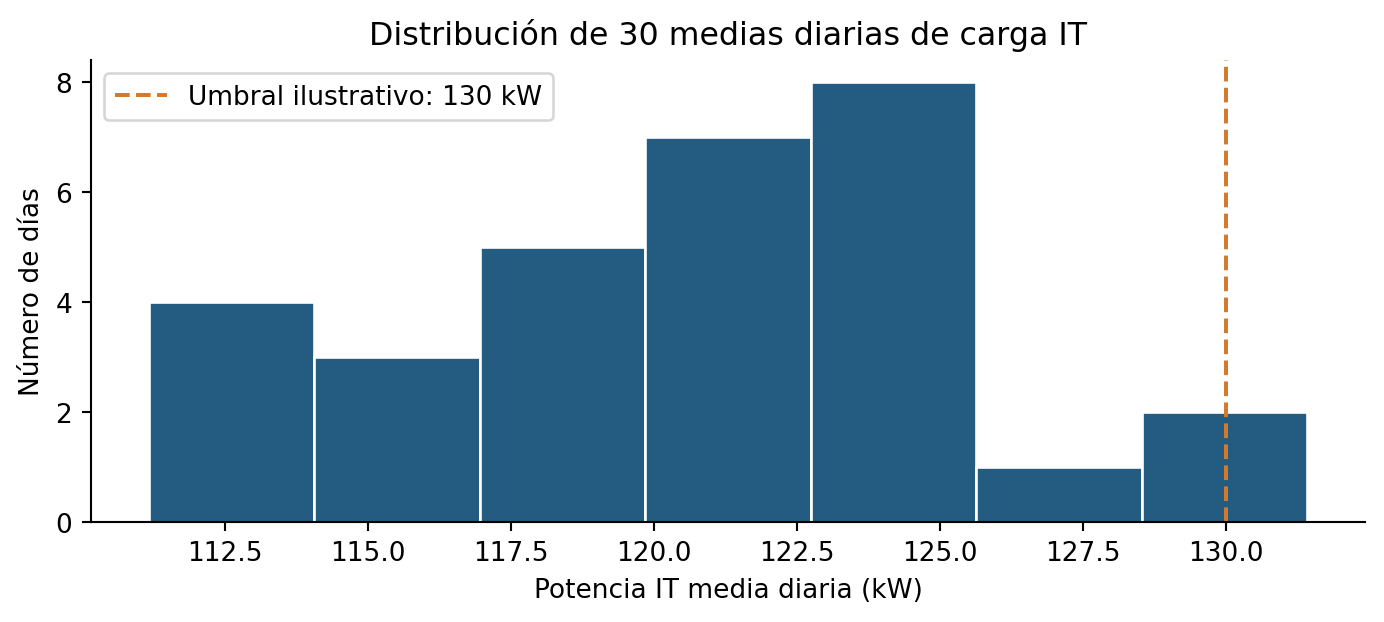

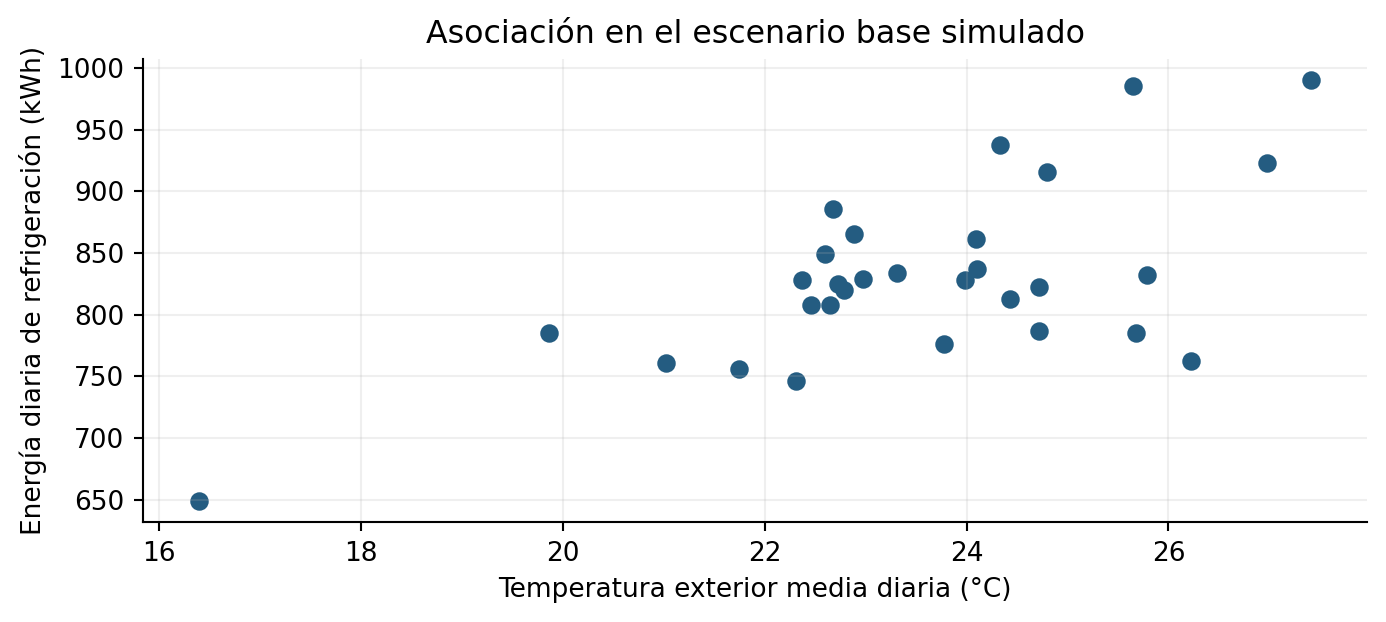

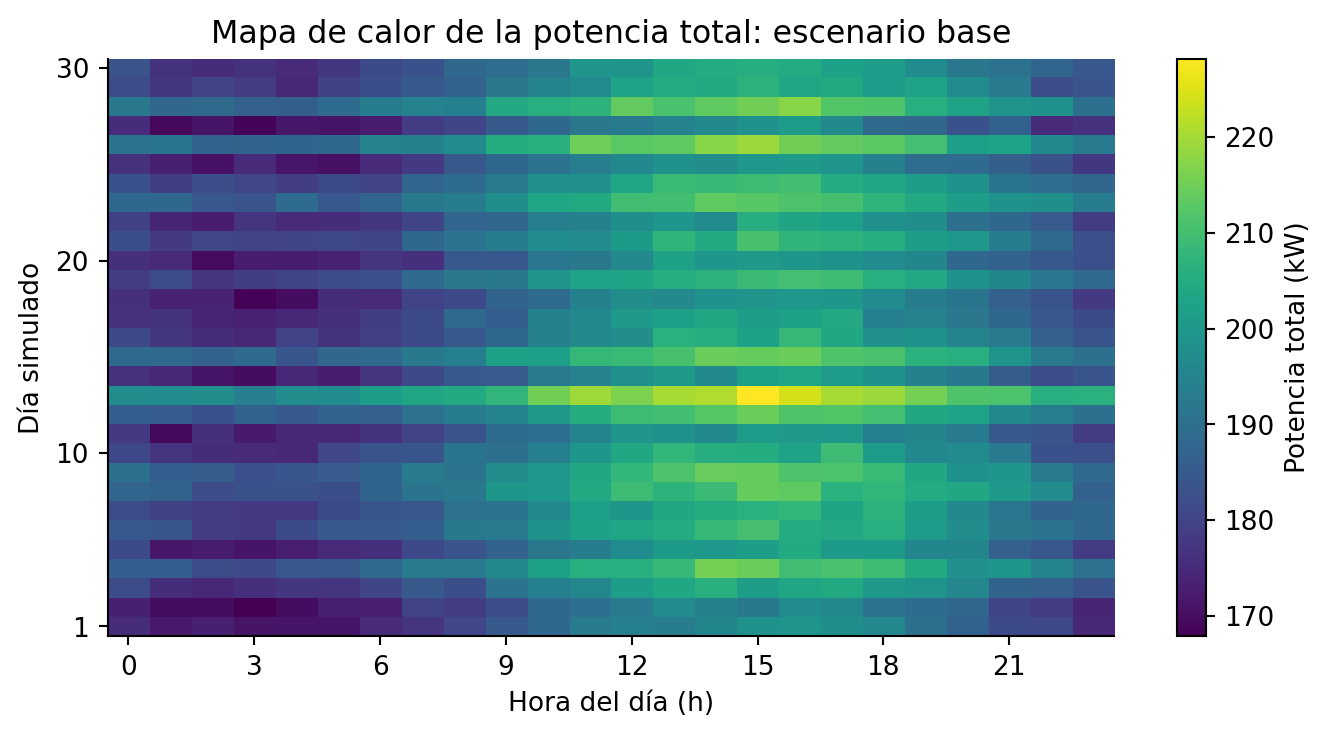

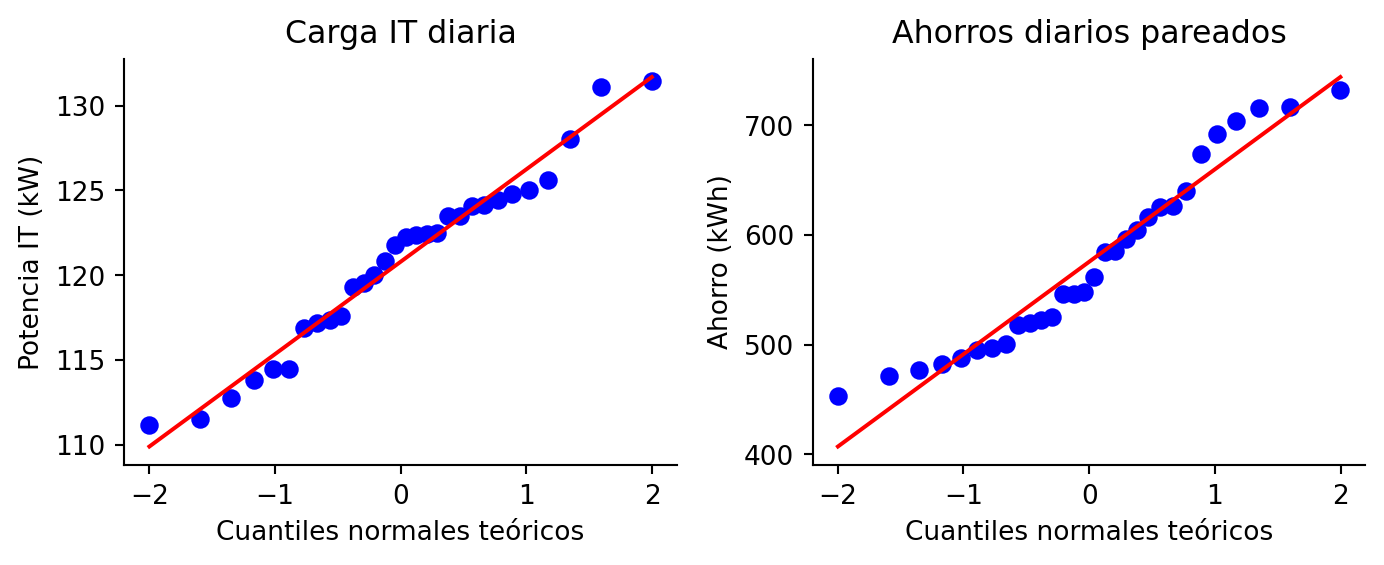

In [7]:
rutas = crear_figuras(limpio, diario, eventos, RAIZ / 'figuras')
for ruta in rutas:
    display(Image(filename=ruta, width=700))


## 9. Contraste de hipótesis
Pregunta: dentro del modelo, ¿es positivo el ahorro medio a igual IT y ambiente?

D = E_base − E_mejorado. H₀: μ_D ≤ 0; H₁: μ_D > 0; α = 0,05. Se aplica t pareada en la frontera μ_D=0.

Hay 30 diferencias diarias, no 720 réplicas independientes. Se informa además un IC bilateral del 95 % para la **media** del ahorro. El IC no describe el rango del 95 % de los días ni garantiza ahorros reales. La reducción ya está supuesta en la simulación.

In [8]:
contraste = contraste_pareado(diario)
print(json.dumps(contraste, ensure_ascii=False, indent=2))
print('Decisión:', 'Rechazar H0 en el modelo simulado' if contraste['p_unilateral'] < CONFIG['alpha'] else 'No rechazar H0')


{
  "n": 30,
  "gl": 29,
  "alpha": 0.05,
  "ahorro_medio_kwh": 575.5491147403961,
  "s_ahorro_kwh": 83.25875762162266,
  "error_estandar_kwh": 15.200899886405969,
  "t_manual": 37.86283174294863,
  "t_scipy": 37.86283174294863,
  "p_unilateral": 1.5153385067349229e-26,
  "ic95_inferior": 544.459783705627,
  "ic95_superior": 606.6384457751652,
  "shapiro_diferencias_p": 0.06369077489681678,
  "ahorro_pct": 12.46517056488196,
  "anualizacion_ilustrativa_kwh": 210075.4268802446
}
Decisión: Rechazar H0 en el modelo simulado


## 10. Verificación y exportación al paper
Se comparan fórmulas alternativas y SciPy; se comprueba el balance horario-diario y la igualdad de cargas por par. Esto verifica código y aritmética, no las hipótesis físicas. Los CSV y el JSON permiten seguir cada cifra del paper.

In [9]:
verificaciones = comprobar_resultados(limpio, diario, prob, contraste)
print(json.dumps(verificaciones, ensure_ascii=False, indent=2))
(RAIZ / 'resultados').mkdir(exist_ok=True)
diario.to_csv(RAIZ / 'resultados' / 'resumen_diario.csv', index=False)
descriptiva_horaria.to_csv(RAIZ / 'resultados' / 'descriptiva_horaria.csv', index=False)
descriptiva_diaria.to_csv(RAIZ / 'resultados' / 'descriptiva_diaria.csv', index=False)
import platform, scipy, matplotlib
pue_periodo = {esc: float(g.e_total_kwh.sum()/g.e_it_kwh.sum())
               for esc, g in diario.groupby('escenario')}
resultados = dict(config=CONFIG, calidad=calidad, relacion=relacion,
    probabilidades=prob, contraste=contraste, pue_periodo=pue_periodo,
    verificaciones=verificaciones,
    entorno=dict(python=platform.python_version(), numpy=np.__version__,
                 pandas=pd.__version__, scipy=scipy.__version__, matplotlib=matplotlib.__version__))
(RAIZ / 'resultados' / 'resultados.json').write_text(
    json.dumps(resultados, ensure_ascii=False, indent=2), encoding='utf-8')
(RAIZ / 'datos' / 'configuracion.json').write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')
print('Ahorro medio para el paper:', round(contraste['ahorro_medio_kwh'], 3), 'kWh/día')


{
  "estado": "CORRECTO",
  "controles": [
    "Carga IT idéntica entre escenarios",
    "Balance de energía horario-diario",
    "Binomial: fórmula vs SciPy",
    "Poisson: fórmula vs SciPy",
    "Normal: erfc vs SciPy",
    "t: cálculo directo vs SciPy",
    "Cálculos centrales de Fase I"
  ]
}
Ahorro medio para el paper: 575.549 kWh/día


## 11. Interpretación de IA y auditoría
La auditoría compara la respuesta de ChatGPT con los resultados de Python. Comprueba los redondeos del ahorro, incorpora el intervalo de confianza y recoge los supuestos de refrigeración y consumos auxiliares del modelo. El registro completo se carga desde `resultados/auditoria_ia.md`.

In [10]:
print((RAIZ / 'resultados' / 'auditoria_ia.md').read_text(encoding='utf-8'))


# Interpretación de IA y auditoría

La respuesta de ChatGPT del 13 de noviembre de 2026 se compara con los resultados calculados en Python.

## 1. Resultados calculados antes de la interpretación

- 30 pares diarios de datos simulados; igual carga IT y ambiente dentro de cada par.
- Consumo medio base: 4.617,258 kWh/día; mejorado: 4.041,709 kWh/día.
- Ahorro medio: 575,549 kWh/día; proporción agregada: 12,465 %.
- IC bilateral 95 % para la media del ahorro: [544,460; 606,638] kWh/día.
- t pareada unilateral: 37,8628; gl=29; p=1,5153e-26.
- Correlación diaria ambiente-refrigeración: r=0,6561 (30 días base).
- La mejora se introduce en el generador: refrigeración común ×0,60 y otros auxiliares −10 kW.

## 2. Prompt aplicado a estos resultados

«Con los resultados anteriores, redacta una explicación breve para un responsable
no técnico y recomienda un siguiente paso. Distingue la simulación de un resultado
real y no conviertas la correlación en causalidad.»

## 3. Respuesta de ChatGPT obj

## 12. Explicación para un responsable
La simulación muestra una diferencia cercana al 12,5 % con la misma carga IT. Es una consecuencia de los supuestos, no una garantía. El paso siguiente sería una prueba piloto con contadores, mediciones térmicas internas y análisis económico. 